In [1]:
###--------------------------------------------LOAD LIBRARIES
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import copy
import os, glob
import random

###--------------------------------------------4 layers
print('Reading anndata')
adata =  sc.read("/home/MRMelissaGrantPeters/MinaRyten/Melissa/spatialDLPFC/nonIF_c2l_anndata_combined_30samples.h5ad")

# Prepare data
subset = adata[adata.obs['bayesSpace_harmony_7'].isin([1,2,3,4,5,6,7])]   # Excluding WM and meningeal layers

subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)
                                                     1 : 'SpD1',
                                                     2 : 'SpD1', 
                                                     3 : 'SpD2', 
                                                     4 : 'SpD3', 
                                                     5 : 'WM',
                                                     6 : 'SpD4',
                                                     7 : 'WM'})

subset.obs['sample_id'] = subset.obs['sample_id'].astype(str)

df_deconvo = subset.obs[np.isnan(subset.obs['Oligo'])==False]

Reading anndata


/tmp/ipykernel_2235037/1485681986.py:18: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  subset.obs['bayesSpace_harmony_7'] = subset.obs['bayesSpace_harmony_7'].replace({   # Renaming to match order of MRI (L1, closer to WM, L4 closer to meninges)


In [7]:
df_all = pd.read_csv('../../raw_data/GSL_genes/Genes_of_interest_GSL-PD.csv')

Reading data
Start pathway scoring
Catabolism
Path does not exist
18


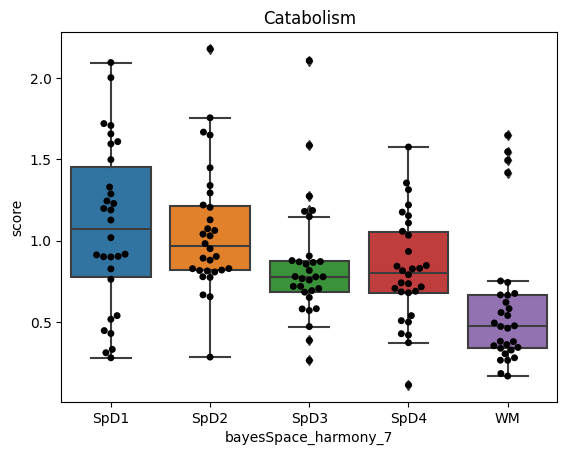

Reading data
Start pathway scoring
Complex GSL synthesis
Path does not exist
21


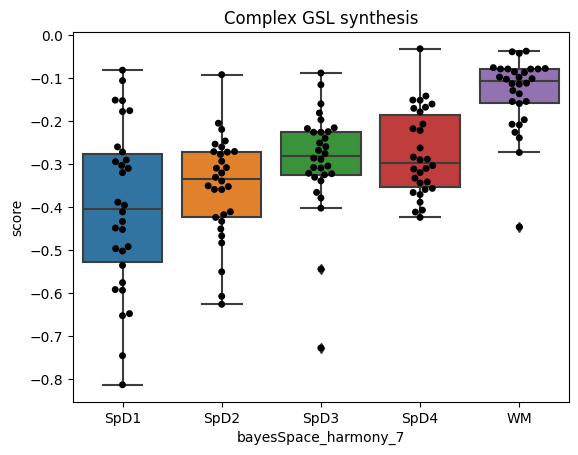

Reading data
Start pathway scoring
Early biosynthesis
Path does not exist
11


/home/MRMelissaGrantPeters/miniconda3/envs/panpipes-hardy/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 6.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/MRMelissaGrantPeters/miniconda3/envs/panpipes-hardy/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


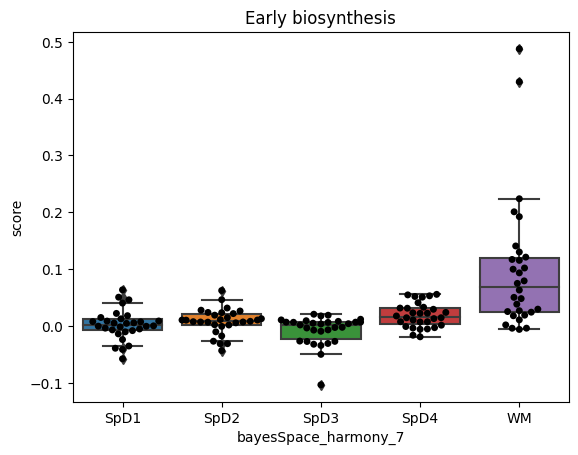

Reading data
Start pathway scoring
Lipid transport
Path does not exist
13


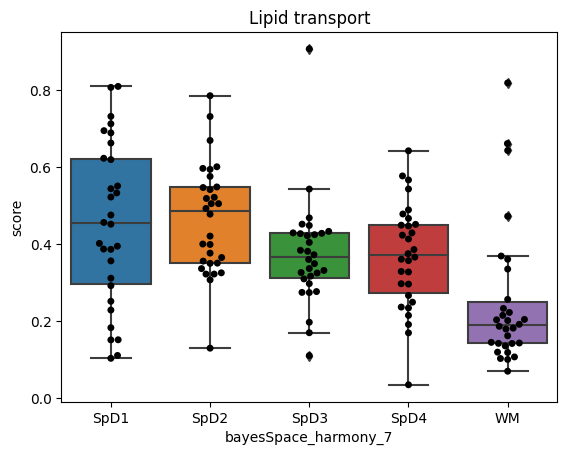

Reading data
Start pathway scoring
Lysosomal transport and trafficking
Path does not exist
14


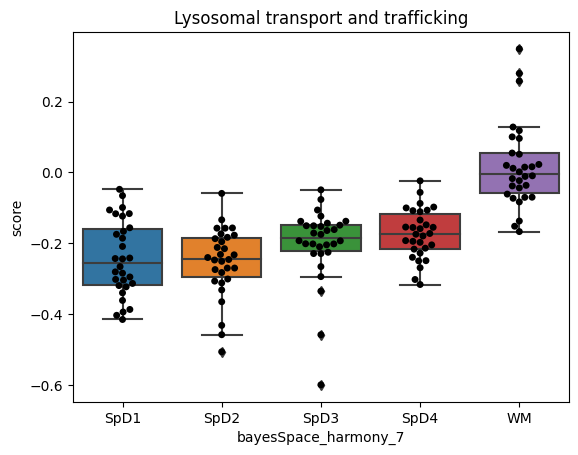

Reading data
Start pathway scoring
PD associated risk gene
Path does not exist
14


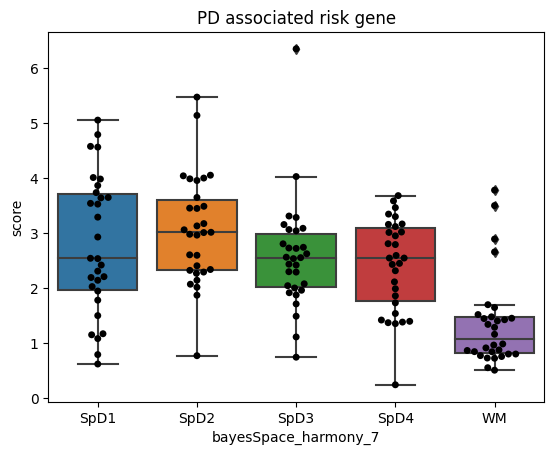

Reading data
Start pathway scoring
PD monogenic gene
Path does not exist
10


In [ ]:
df_all = df_all.replace({'Lysosomal transport/trafficking': 'Lysosomal transport and trafficking'})
categories = df_all['Category'].unique()

for m in range(0,len(categories)):
    print('Reading data')
    category = categories[m] # Fetch category name
    df = df_all[df_all['Category']==category]  # Fetch gene and pathway information for a category
    
    print('Start pathway scoring')
    print(category)
    
    genes = list(df['Gene'])  # list genes
    #  Check if this has already been run for this pathway and if the gene list for the pathway is 1 gene or less. Stop this loop and continue if either are true
    
    if (os.path.exists('../../processed_data/10_GSL_characterisation/scores_4layers_%s.csv' % (category)) | len(genes)<3):
        print('Path exists or not enough genes')
        continue
    else:
        print('Path does not exist')
        ensembl = list(subset.var[subset.var['gene_name'].isin(genes)].index)     # List ensembl ids for gene list to match spatial data
        print(len(genes))
        for it in range(0,1000): #  Create a background of test genes with bootstrapping
            universe = list(subset.var.index)
            gene_pool = list(set(universe)-set(ensembl))                           
            interest = subset[:, ensembl].to_df().sum(axis = 1)                    #Take the sum of gene expression for genes of interest                     
            r = random.sample(gene_pool, len(ensembl))
            background = subset[:, r].to_df().sum(axis = 1)                        #Take sum of expression for background genes
            subset.obs['score'] = (interest - background)/subset.obs['sum_umi']    # Divide sum of gene signal by total UMIs to compensate for poor permeabilisation of WM
            df1 = subset.obs[['sample_id','bayesSpace_harmony_7','score']]
            if (it == 0):
                all_scores = subset.obs[['bayesSpace_harmony_7','sample_id','score']]
            else: 
                all_scores = pd.concat([all_scores, subset.obs['score']], axis = 1)
    
        median  = all_scores.groupby(by = ['sample_id', 'bayesSpace_harmony_7']).sum().median(axis=1).reset_index().rename(columns={0 : 'score'})
        sns.boxplot(data=median, x="bayesSpace_harmony_7", y="score")
        sns.swarmplot(data=median, x="bayesSpace_harmony_7", y="score", color = 'black')
        plt.title(categories[m])
        plt.savefig('../../plots/10_GSL_characterisation/scores_4layers_%s.png' % (category), bbox_inches='tight')
        plt.show()
        plt.clf()
                
        median.to_csv('../../processed_data/10_GSL_characterisation/scores_4layers_%s.csv' % (category))
